# LeNet

LeNet-5 описали Ян Лекун и соавторы в 1998 году в работе о распознавании документов. Модель создавали для рукописных цифр: свёртки выделяли признаки, пулинг уменьшал карты признаков, а последние слои определяли класс. [Оригинальная статья](https://leon.bottou.org/papers/lecun-98h).

Здесь проверим, как LeNet-5 справится с цветными изображениями CIFAR-10 размером 32×32. Вместо одного канала первый свёрточный слой у нас принимает три. Оставляем три свёртки с `Tanh` и два слоя среднего пулинга, а на выходе получаем 10 чисел - логиты для каждого из классов.

Ниже показана наша адаптация LeNet.

<img src="images/lenet5.svg" alt="Схема LeNet-5" height="600">

In [1]:
import torch.nn as nn
import torch
import pandas as pd
from typing import Callable
from torch.utils.data import TensorDataset
import sys
sys.path.append("../utils")
from data_utils import images_to_tensor, train_dataset_split, create_dataloader, calculate_mean_std, AutoAugumentationDataset, StandardizationDataset, TestImagesDataset

In [2]:
SEED = 52
torch.manual_seed(SEED)

## Работа с данными

In [3]:
X_train, y_train = images_to_tensor(
    "../data/train",
    "../data/trainLabels.csv",
)

Разделим размеченные данные на train и val: 80% изображений пойдут на обучение, а оставшиеся 20% — на проверку после каждой эпохи

In [4]:
ds_train = TensorDataset(X_train, y_train)

In [5]:
ds_train, ds_val = train_dataset_split(ds_train, train_size=0.8, random_seed=SEED)

### Стандартизация и аугментация данных

После разделения данных вычислим среднее и стандартное отклонение каждого цветового канала по train. По этим значениям стандартизируем train, val и test.

К train перед стандартизацией применим `AutoAugmentPolicy.CIFAR10`. При каждом обращении к изображению стратегия случайно выбирает одну из подготовленных пар операций. Каждая операция срабатывает со своей вероятностью. Среди них есть:

- Геометрические изменения: поворот (Rotate), сдвиг по горизонтали и вертикали (TranslateX, TranslateY), наклон (ShearY).
- Изменения цвета и тона: яркость (Brightness), насыщенность (Color), контраст (Contrast), резкость (Sharpness), инверсия (Invert), соляризация (Solarize), уменьшение числа цветов (Posterize), автоматическая настройка контраста (AutoContrast) и выравнивание гистограммы (Equalize).

Val и test проходят только стандартизацию, без аугментации.

Примеры того, как меняются изображения:
- 1.png: лягушка сдвинута вправо
- 2.png: грузовик сдвинут вверх
- 7.png: птица стала темнее
- 8.png: у лошади изменились цвета и контраст

<img src="images/autoaugment_examples.png" alt="Примеры AutoAugment" width="450">

In [6]:
# считаем mean и std только по исходным картинкам из train
mean, std = calculate_mean_std(ds_train)

ds_train_aug = AutoAugumentationDataset(ds_train)
ds_train_ready = StandardizationDataset(ds_train_aug, mean, std)
ds_val_ready = StandardizationDataset(ds_val, mean, std)

In [18]:
BATCH_SIZE = 2048

In [19]:
dl_train = create_dataloader(ds_train_ready, BATCH_SIZE, shuffle=True, random_seed=SEED)
dl_val = create_dataloader(ds_val_ready, BATCH_SIZE, shuffle=False, random_seed=SEED)

## Создание класса LeNet

In [20]:
class LeNet5(nn.Module):
    """Упрощённая адаптация LeNet-5 для изображений CIFAR-10 размером 32x32."""

    def __init__(
        self,
        in_channels: int = 3,
        output_size: int = 10,
        image_size: tuple[int, int] = (32, 32)
    ):

        super().__init__()

        modules = []
        conv_layers = [6, 16, 120]

        in_ = in_channels # количество входных каналов для свёртки
        for i in range(len(conv_layers)): # цикл добавления свёрточных слоёв, 1 слой - (свёртка + активация + пуллинг)

            # свёртка
            modules.append(nn.Conv2d(
                in_channels=in_,
                out_channels=conv_layers[i],
                kernel_size=5,
                stride=1,
                padding=0,
            ))
            in_ = conv_layers[i]

            modules.append(nn.Tanh()) # слой активации после какждой свёртки

            if i != len(conv_layers)-1: # после каждой свёртки кроме последней добавляем слой пулинга
                modules.append(nn.AvgPool2d(kernel_size=2, stride=2))

        #вычиляем на искусственном примере размер картинки, который получился после всех свёрток
        with torch.no_grad():
            sample = torch.zeros(1, in_channels, *image_size)
            in_features = nn.Sequential(*modules)(sample).flatten(1).shape[1]

        # после всех свёрточных слоёв распрямляем значения в вектор, чтобы подать на вход линейному слою
        modules.append(nn.Flatten())

        # линейный слой на 84 нейрона
        modules.append(nn.Linear(in_features, 84))
        modules.append(nn.Tanh())

        # в конце добавляем выходной слой, дающий предсказания (логиты) для каждого из классов
        modules.append(nn.Linear(84, output_size))

        self.network = nn.Sequential(*modules)

    def forward(self, x):
        return self.network(x)

In [21]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Устройство: {DEVICE}")

Устройство: mps


In [22]:
lenet5 = LeNet5().to(DEVICE)
loss_func = nn.CrossEntropyLoss()
# weight_decay=1e-4 - небольшой стартовый штраф т.к. AutoAugment уже есть,
# поэтому не усиливаем регуляризацию слишком сильно
optimizer = torch.optim.Adam(lenet5.parameters(), lr=5e-4, weight_decay=1e-4)

## Обучение

In [23]:
import sys
sys.path.append("../utils")
from train_utils import train, test

Обучим модель и сохраним веса той эпохи, на которой точность на val окажется самой высокой

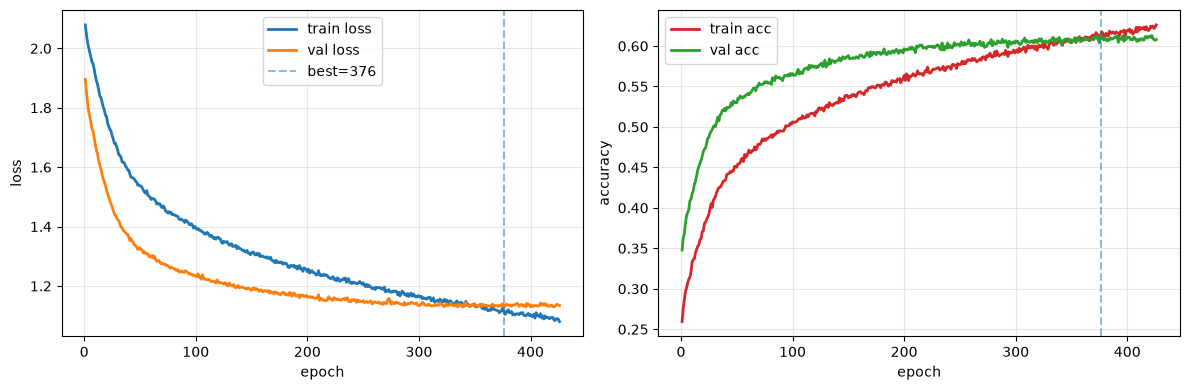

Ранняя остановка на эпохе 426: val_acc не улучшалась 50 эпох
Best epoch = 376, best val_acc = 0.6139


,0
0,0.6139
1,376.0000


In [25]:
train(lenet5, optimizer, loss_func, dl_train, dl_val, "models/lenet5.pth", DEVICE, EPOCH_COUNT=1000, patience=50, log_every=1)

## Тестирование

Загрузим веса лучшей эпохи. Тестовые картинки будем читать батчами в порядке `sampleSubmission.csv`, затем сохраним предсказания в файл submission.

In [ ]:
lenet_best = LeNet5(3, 10, (32, 32)).to(DEVICE)
lenet_best.load_state_dict(torch.load('models/lenet5.pth', map_location=DEVICE))
lenet_best.eval()

In [ ]:
ds_test = TestImagesDataset(
    "../data/test",
    "../data/sampleSubmission.csv",
)

In [ ]:
ds_test_ready = StandardizationDataset(ds_test, mean, std)
dl_test = create_dataloader(ds_test_ready, batch_size=BATCH_SIZE, shuffle=False)
class_names = sorted(pd.read_csv("../data/trainLabels.csv")["label"].unique())

In [ ]:
submission = test(
    lenet_best,
    dl_test,
    class_names,
    "../data/sampleSubmission.csv",
    "lenet_submission.csv",
    DEVICE,
)

## Итог

В ходе работы была реализована и обучена адаптированная архитектура **LeNet-5** для классификации изображений датасета CIFAR-10. До добавления аугментации и стандартизации максимальная точность на валидационной выборке составила **57,11 %** и была достигнута на 225-й эпохе.

Результат объясняется особенностями архитектуры, предложенной в 1998 году преимущественно для распознавания рукописных символов. По сравнению с более современными сетями LeNet-5 имеет относительно простую структуру и ограниченные возможности извлечения сложных признаков, необходимых для классификации цветных изображений. Тем не менее для архитектуры своего времени LeNet-5 стала значимым достижением и продемонстрировала применимость свёрточных нейронных сетей к задачам распознавания изображений.
